# **1. Perkenalan Dataset**

Dataset yang dipakai adalah **AI4I 2020 Predictive Maintenance Dataset** dari UCI Machine Learning Repository
(id 601), berlisensi Creative Commons Attribution 4.0 International. Berkas `ai4i2020.csv` berisi 10.000 baris
data sintetis yang meniru kondisi mesin produksi di industri.

Sumber: https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

Isi kolomnya:

| Kolom | Arti |
|-------|------|
| `UDI`, `Product ID` | nomor urut dan kode produk (identitas) |
| `Type` | kualitas produk: L (rendah), M (sedang), H (tinggi) |
| `Air temperature [K]`, `Process temperature [K]` | suhu udara dan suhu proses |
| `Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]` | kecepatan putar, torsi, dan keausan alat |
| `Machine failure` | **target**: 1 jika mesin gagal, 0 jika tidak |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | lima mode kegagalan yang membentuk nilai `Machine failure` |

Tujuan eksperimen ini adalah menyiapkan data agar model klasifikasi dapat memprediksi `Machine failure`
dari kondisi operasi mesin.

# **2. Import Library**

Pustaka yang dibutuhkan: `pandas` dan `numpy` untuk data, `matplotlib` untuk grafik, serta `scikit-learn`
untuk pembagian data dan transformasi fitur.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 120)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.2.1


# **3. Memuat Dataset**

Berkas CSV dibaca dengan `pandas`. Berkas ini diawali tanda BOM UTF-8, sehingga dibaca dengan
`encoding="utf-8-sig"` agar nama kolom pertama tidak terbawa karakter tambahan.

In [2]:
PATH_RAW = os.path.join("..", "ai4i2020_raw", "ai4i2020.csv")
data = pd.read_csv(PATH_RAW, encoding="utf-8-sig")
print("Jumlah data awal: %d baris, %d kolom" % data.shape)
data.head()

Jumlah data awal: 10000 baris, 14 kolom


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Tipe data dan jumlah nilai tidak kosong pada setiap kolom.

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

# **4. Exploratory Data Analysis (EDA)**

EDA dimulai dari ringkasan statistik, lalu nilai kosong, data duplikat, keseimbangan kelas, sebaran fitur,
dan korelasi.

In [4]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


Pemeriksaan nilai kosong dan baris duplikat.

In [5]:
print("Nilai kosong per kolom:")
print(data.isna().sum().to_string())
print("Baris duplikat:", int(data.duplicated().sum()))

Nilai kosong per kolom:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
Baris duplikat: 0


Tidak ada nilai kosong dan tidak ada baris duplikat. Selanjutnya keseimbangan kelas pada target dan sebaran
kolom `Type`.

Distribusi target:
Machine failure
0    9661
1     339
Porsi kelas 1: 0.0339

Distribusi Type:
Type
L    6000
M    2997
H    1003


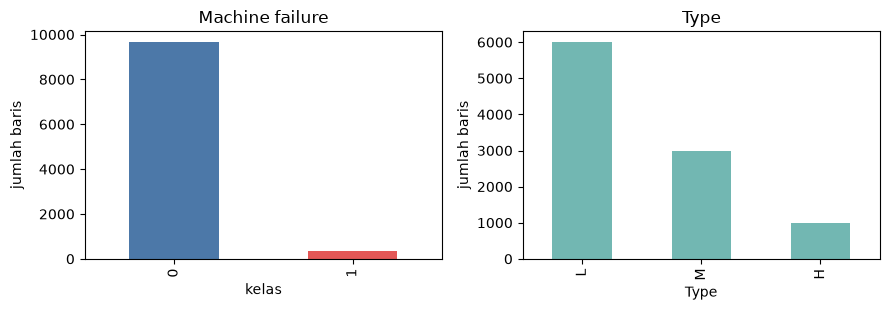

In [6]:
hitung_target = data["Machine failure"].value_counts().sort_index()
print("Distribusi target:")
print(hitung_target.to_string())
print("Porsi kelas 1: %.4f" % (hitung_target[1] / len(data)))
print()
print("Distribusi Type:")
print(data["Type"].value_counts().to_string())

fig, sumbu = plt.subplots(1, 2, figsize=(9, 3.2))
hitung_target.plot.bar(ax=sumbu[0], color=["#4c78a8", "#e45756"])
sumbu[0].set_title("Machine failure")
sumbu[0].set_xlabel("kelas")
sumbu[0].set_ylabel("jumlah baris")
data["Type"].value_counts().plot.bar(ax=sumbu[1], color="#72b7b2")
sumbu[1].set_title("Type")
sumbu[1].set_ylabel("jumlah baris")
plt.tight_layout()
plt.show()

Hanya sekitar 3,4 persen baris berkelas 1, jadi data sangat tidak seimbang. Pembagian data nanti harus
stratifikasi agar porsi kelas 1 sama di data latih dan data uji.

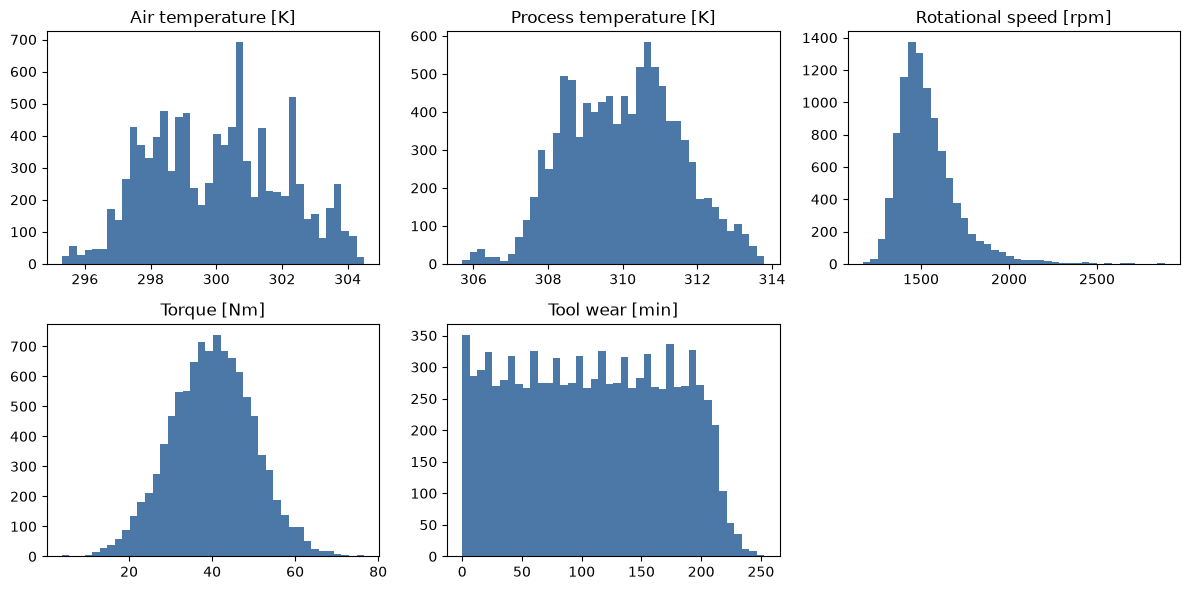

In [7]:
NUMERIK = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
           "Torque [Nm]", "Tool wear [min]"]

fig, sumbu = plt.subplots(2, 3, figsize=(12, 6))
for ax, kolom in zip(sumbu.ravel(), NUMERIK):
    ax.hist(data[kolom], bins=40, color="#4c78a8")
    ax.set_title(kolom)
sumbu.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

Rata-rata fitur pada mesin yang gagal dibandingkan dengan yang tidak gagal.

In [8]:
# perbandingan rata-rata fitur antara mesin yang gagal dan yang tidak
data.groupby("Machine failure")[NUMERIK].mean().round(2)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.97,310.00,1540.26,39.63,106.69
1,300.89,310.29,1496.49,50.17,143.78


Korelasi antar kolom numerik dan dengan target.

Air temperature [K]        0.083
Process temperature [K]    0.036
Rotational speed [rpm]    -0.044
Torque [Nm]                0.191
Tool wear [min]            0.105
Machine failure            1.000


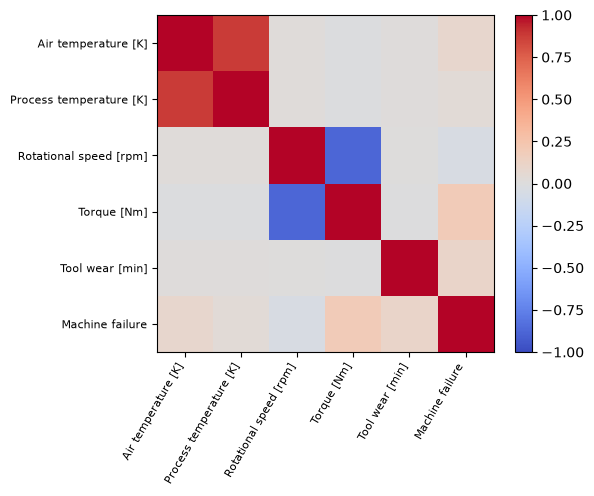

In [9]:
korelasi = data[NUMERIK + ["Machine failure"]].corr()
print(korelasi["Machine failure"].round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 5))
gambar = ax.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(korelasi)))
ax.set_yticks(range(len(korelasi)))
ax.set_xticklabels(korelasi.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticklabels(korelasi.columns, fontsize=8)
fig.colorbar(gambar)
plt.tight_layout()
plt.show()

Suhu udara dan suhu proses berkorelasi kuat satu sama lain, begitu juga kecepatan putar dan torsi
(berkorelasi negatif). Itu wajar untuk data mesin dan tidak dibuang, karena model berbasis pohon tidak
terganggu oleh korelasi antar fitur.

Kolom `TWF`, `HDF`, `PWF`, `OSF`, dan `RNF` perlu diperiksa: menurut deskripsi dataset, kelima kolom ini
adalah penyebab kegagalan. Jika salah satunya bernilai 1, maka `Machine failure` ikut bernilai 1.

In [10]:
MODE = ["TWF", "HDF", "PWF", "OSF", "RNF"]
ada_mode = data[MODE].max(axis=1)
print(pd.crosstab(ada_mode, data["Machine failure"], rownames=["ada mode kegagalan"]))

Machine failure        0    1
ada mode kegagalan           
0                   9643    9
1                     18  330


Tabel menunjukkan bahwa 330 dari 339 kegagalan sudah ditandai oleh salah satu kolom mode (ada 9 kegagalan tanpa
tanda dan 18 baris bertanda yang berlabel tidak gagal, jadi hubungannya tidak sempurna). Kolom-kolom itu
baru diketahui setelah mesin gagal, sehingga memakainya sebagai fitur berarti model "mengintip" jawaban
(kebocoran data). Kolom itu dibuang pada tahap preprocessing.

# **5. Data Preprocessing**

Langkah preprocessing yang dipilih berdasarkan hasil EDA:

1. **Nilai kosong dan duplikat**: tidak ada, jadi tidak ada baris yang dihapus.
2. **Membuang kolom identitas** (`UDI`, `Product ID`): hanya penanda baris, tidak membawa informasi mesin.
3. **Membuang kolom mode kegagalan** (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`): kebocoran data, seperti dijelaskan
   di bagian EDA.
4. **Pembagian data** 80% latih dan 20% uji, stratifikasi pada target, `random_state=42`.
5. **Encoding** kolom `Type` dengan one-hot (`Type_H`, `Type_L`, `Type_M`).
6. **Standarisasi** lima kolom numerik dengan `StandardScaler`. Rata-rata dan simpangan baku dipelajari
   hanya dari data latih, lalu dipakai untuk data uji.

Outlier tidak dihapus: nilai ekstrem pada torsi dan keausan alat justru berkaitan dengan kegagalan mesin,
sedangkan model berbasis pohon yang dipakai pada tahap berikutnya tidak sensitif terhadap outlier. Binning
tidak diperlukan.

In [11]:
KOLOM_IDENTITAS = ["UDI", "Product ID"]
data_bersih = data.drop(columns=KOLOM_IDENTITAS + MODE)
print("Kolom tersisa:", list(data_bersih.columns))

Kolom tersisa: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


Data dibagi menjadi data latih dan data uji sebelum standarisasi, supaya data uji tidak ikut menentukan
rata-rata dan simpangan baku.

In [12]:
fitur = data_bersih.drop(columns=["Machine failure"])
target = data_bersih["Machine failure"]
x_latih, x_uji, y_latih, y_uji = train_test_split(
    fitur, target, test_size=0.2, random_state=42, stratify=target
)
print("Data latih: %d | Data uji: %d" % (len(x_latih), len(x_uji)))
print("Porsi kelas 1 latih: %.4f | uji: %.4f" % (y_latih.mean(), y_uji.mean()))

Data latih: 8000 | Data uji: 2000
Porsi kelas 1 latih: 0.0339 | uji: 0.0340


Transformer dilatih hanya pada data latih, lalu dipakai untuk data latih dan data uji.

In [13]:
preprocessor = ColumnTransformer(
    [
        ("numerik", StandardScaler(), NUMERIK),
        ("type", OneHotEncoder(categories=[["H", "L", "M"]], sparse_output=False), ["Type"]),
    ]
)
preprocessor.fit(x_latih)

NAMA_KOLOM = ["Air_temperature_K", "Process_temperature_K", "Rotational_speed_rpm", "Torque_Nm",
              "Tool_wear_min", "Type_H", "Type_L", "Type_M"]
latih = pd.DataFrame(preprocessor.transform(x_latih), columns=NAMA_KOLOM, index=x_latih.index)
uji = pd.DataFrame(preprocessor.transform(x_uji), columns=NAMA_KOLOM, index=x_uji.index)
latih["Machine_failure"] = y_latih.astype(int).to_numpy()
uji["Machine_failure"] = y_uji.astype(int).to_numpy()
latih.head()

,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Type_H,Type_L,Type_M,Machine_failure
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,0.0,0.0,1.0,0
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0.0,0.0,1.0,0
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0.0,0.0,1.0,0
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.0,1.0,0.0,0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0.0,1.0,0.0,0


Pemeriksaan hasil standarisasi pada data latih.

In [14]:
# pemeriksaan: rata-rata dan simpangan baku data latih setelah standarisasi
print(latih[NAMA_KOLOM[:5]].agg(["mean", "std"]).round(3).to_string())
print("Nilai kosong latih/uji:", int(latih.isna().sum().sum()), int(uji.isna().sum().sum()))

      Air_temperature_K  Process_temperature_K  Rotational_speed_rpm  Torque_Nm  Tool_wear_min
mean                0.0                    0.0                   0.0       -0.0           -0.0
std                 1.0                    1.0                   1.0        1.0            1.0
Nilai kosong latih/uji: 0 0


Rata-rata mendekati 0 dan simpangan baku mendekati 1 pada data latih. Hasil akhir disimpan ke folder
`ai4i2020_preprocessing` dalam bentuk `train.csv` dan `test.csv`. Langkah yang sama dijalankan otomatis oleh
`automate_Aunuun-Jeffry-Mahbuubi.py`.

In [15]:
OUT = "ai4i2020_preprocessing"
os.makedirs(OUT, exist_ok=True)
latih.to_csv(os.path.join(OUT, "train.csv"), index=False, lineterminator="\n")
uji.to_csv(os.path.join(OUT, "test.csv"), index=False, lineterminator="\n")
print("Tersimpan:", sorted(os.listdir(OUT)))

Tersimpan: ['columns.json', 'preprocessor.joblib', 'test.csv', 'train.csv']
